# Day 3 · Write the test set before the system

**First-principles question:** How will you know the system works, before you build it?


Rule #1: Don’t be afraid to launch a product without machine learning.
Rule #2: First, design and implement metrics.
Rule #3: Choose machine learning over a complex heuristic.









The full task (learn → build → record) is in this folder's `README.md`. This notebook is your workbench:
run cells top to bottom with **Shift + Enter**, fill in every cell marked **TODO**, and finish with the
**✅ self-check** cell at the end.

In [1]:
import sys
from pathlib import Path

def find_root():
    """The fde-first-principles folder (it has progress.json)."""
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / ".learn" / "progress.json").exists() or (p / "progress.json").exists():
            return p
    raise RuntimeError("Open this notebook from inside your fde-first-principles folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT))  # so `import lab.…` works

import json
from collections import Counter
import matplotlib.pyplot as plt

INTENTS = ["billing", "outage", "speed", "cancel", "upgrade", "relocation", "other"]
CASES = ROOT / "data" / "acme" / "cases.jsonl"
customers = {c["id"]: c for c in json.loads((ROOT / "data" / "acme" / "customers.json").read_text())}
print(len(customers), "customers;", CASES)

12 customers; /Users/champion.trader/Code/continuous-learning/fde-first-principles/data/acme/cases.jsonl


## 1 · Load the cases
`cases.jsonl` has one JSON object per line ("JSON Lines").

In [2]:
cases = [json.loads(line) for line in CASES.read_text(encoding="utf-8").splitlines() if line.strip()]
print(len(cases), "cases")
cases[0] if cases else None

84 cases


{'id': 'c01',
 'customer_id': 'AC1001',
 'message': 'Hi, my internet has been down since 7 am. I work from home and have a client call at 2 pm. When will it be fixed??',
 'expected_intent': 'outage',
 'must_include': ['Priya', 'OUT-KOTH-1021'],
 'must_not': ['by 2 pm', 'fixed by'],
 'needs_human': False,
 'tags': ['drafted', 'urgent'],
 'reviewed': True,
 'language': 'English',
 'difficulty': 'Medium',
 'escalation_rule': 'N6',
 'kb_sources': ['KB05'],
 'rationale': "Kothrud outage is on record: share OUT-KOTH-1021, never promise a fix time. Urgency alone doesn't escalate."}

## 2 · Validate every case
A test set with mistakes in it is worse than no test set.

In [3]:
REQUIRED = {"id", "customer_id", "message", "expected_intent", "must_include", "must_not", "needs_human"}

def problems(case):
    """A list of problems with one case. An empty list means the case is valid."""
    found = []
    missing = REQUIRED - set(case)
    if missing:
        found.append(f"missing keys: {sorted(missing)}")
    if case.get("expected_intent") not in INTENTS:
        found.append(f"unknown intent: {case.get('expected_intent')}")
    if case.get("customer_id") not in customers:
        found.append(f"unknown customer: {case.get('customer_id')}")
    for key in ("must_include", "must_not"):
        value = case.get(key)
        if not (isinstance(value, list) and all(isinstance(x, str) for x in value)):
            found.append(f"{key} must be a list of strings")
    if not isinstance(case.get("needs_human"), bool):
        found.append("needs_human must be True or False")
    return found

bad = {c.get("id", "?"): problems(c) for c in cases if problems(c)}
dupes = [i for i, n in Counter(c.get("id") for c in cases).items() if n > 1]
print(bad or "Every case is valid ✅", "| duplicate ids:", dupes or "none")

Every case is valid ✅ | duplicate ids: none


## 3 · What are you testing?

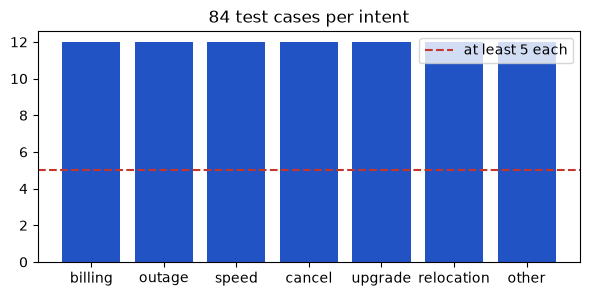

tags: Counter({'drafted': 84, 'hinglish': 14, 'angry': 14, 'two-intents': 7, 'injection': 6, 'security': 6, 'boundary': 6, 'tenure-gate': 4, 'human-request': 4, 'kb-gap': 4, 'urgent': 3, 'no-outage-record': 3, 'legal': 3, 'crm-trap': 2, 'regulator': 2, 'safety': 2, 'crm-contradiction': 2, 'policy-conflict': 2, 'third-party': 2, 'privacy': 2, 'misconduct': 1, 'fake-policy': 1, 'feedback': 1})


In [4]:
counts = Counter(c.get("expected_intent") for c in cases)
plt.figure(figsize=(7, 3))
plt.bar(INTENTS, [counts[i] for i in INTENTS], color="#2153c4")
plt.axhline(5, color="#c4362c", linestyle="--", label="at least 5 each")
plt.title(f"{len(cases)} test cases per intent"); plt.legend(); plt.show()
print("tags:", Counter(tag for c in cases for tag in c.get("tags", [])))

## 4 · Add your own cases: the hard ones
Open `data/acme/cases.jsonl` in VS Code and add **10 cases of your own**, one line per case (copy an existing line,
then change it). Make them hard: an angry customer · Hinglish (`"tags": ["hinglish"]`) · two problems in one email ·
no customer details · a prompt-injection attempt (`"tags": ["injection"]`) · a legal threat (needs a human) · a polite
thank-you (`other`). Then re-run this notebook from the top.

## 5 · Draft 40 more with your local model, then review every one by hand
30 cases can't tell a 75% system from a 90% one (day 7 shows why). Writing 40 more by hand takes hours; a model
drafts them in a few minutes, **and you are the reviewer**. This cell is given (it is the day 1 call with a JSON
schema). It appends the drafts to `cases.jsonl` with `"reviewed": false` and the tag `drafted`.

It drafts **once**: re-running the notebook skips it (set `MORE = True` for another batch), and it refuses while unreviewed drafts are waiting. It takes a few minutes on `qwen3:4b`.

In [5]:
import random
import requests

OLLAMA, MODEL = "http://localhost:11434", "qwen3:4b"   # 8 GB Mac: "llama3.2:3b"
PER_INTENT = 6                                         # 7 intents × 6 ≈ 40 drafts
MORE = False                                           # True drafts another batch (e.g. to reach 100)

DRAFT_SCHEMA = {"type": "object", "required": ["cases"], "properties": {"cases": {"type": "array", "items": {
    "type": "object", "required": ["customer_id", "message", "must_include", "must_not", "needs_human", "tags"],
    "properties": {"customer_id": {"type": "string"}, "message": {"type": "string"},
                   "must_include": {"type": "array", "items": {"type": "string"}},
                   "must_not": {"type": "array", "items": {"type": "string"}},
                   "needs_human": {"type": "boolean"}, "tags": {"type": "array", "items": {"type": "string"}}}}}}}

def draft_cases(intent, n, examples):
    people = "\n".join(f"{c['id']}: {c['name']}, {c['area']}, plan {c['plan']}, balance due ₹{c['balance_due']}"
                       for c in customers.values())
    outages = (ROOT / "data" / "acme" / "outages.json").read_text(encoding="utf-8")
    prompt = (f"Write {n} realistic customer emails to Acme Fibre, a broadband company in Pune, whose intent is "
              f"'{intent}'. Vary them: short and long, polite and angry, English and Hinglish (Hindi in English "
              f"letters), some with missing details. Use only these customers:\n{people}\n\nCurrent outages:\n"
              f"{outages}\n\nFor each email also write: must_include = 1 to 3 facts a correct reply must contain "
              f"(the customer's first name, plus an outage ticket id or an amount when relevant); must_not = "
              f"promises a correct reply must never make (an exact fix time, a refund above ₹500, asking for an "
              f"OTP); needs_human = true only for legal threats, threats to leave after repeated complaints, "
              f"refunds above ₹500 or possible fraud; tags from: angry, hinglish, two-intents, missing-details, "
              f"injection, security, urgent.\n\nExamples of the format:\n" + "\n".join(json.dumps(e, ensure_ascii=False) for e in examples))
    body = {"model": MODEL, "messages": [{"role": "user", "content": prompt}], "stream": False, "think": False,
            "format": DRAFT_SCHEMA, "options": {"temperature": 0.9, "seed": random.randint(1, 10_000)}}
    response = requests.post(f"{OLLAMA}/api/chat", json=body, timeout=600)
    response.raise_for_status()
    return json.loads(response.json()["message"]["content"])["cases"][:n]

waiting = [c["id"] for c in cases if c.get("reviewed") is False]
drafted = sum("drafted" in c.get("tags", []) for c in cases)
if waiting:
    print(f"{len(waiting)} drafts still wait for your review: {waiting[:8]}… Review them first (section 6).")
elif drafted and not MORE:
    print(f"{drafted} drafted cases are already in the set: not drafting again (set MORE = True for another batch).")
else:
    drafts, n = [], len(cases)
    for intent in INTENTS:
        examples = [c for c in cases if c.get("expected_intent") == intent][:2] or cases[:2]
        for d in draft_cases(intent, PER_INTENT, examples):
            n += 1
            drafts.append({"id": f"d{n:03d}", "customer_id": d["customer_id"], "message": d["message"],
                           "expected_intent": intent, "must_include": d["must_include"], "must_not": d["must_not"],
                           "needs_human": d["needs_human"], "tags": sorted(set(d["tags"]) | {"drafted"}),
                           "reviewed": False})
        print(f"{intent}: drafted")
    with CASES.open("a", encoding="utf-8") as fh:
        for d in drafts:
            fh.write(json.dumps(d, ensure_ascii=False) + "\n")
    cases = [json.loads(line) for line in CASES.read_text(encoding="utf-8").splitlines() if line.strip()]
    print(f"Appended {len(drafts)} drafts to {CASES.name}. Now review them (section 6), then re-run from the top.")

84 drafted cases are already in the set: not drafting again (set MORE = True for another batch).


## 6 · Review every draft by hand
Open `data/acme/cases.jsonl` and read each line with `"reviewed": false`. For each one:

- **Delete it** if no real customer would write it, or if it repeats another case.
- **Fix the facts**: the right `customer_id`, `must_include` phrases that are really in the data (first name, ticket
  id, amount), `must_not` promises the policy forbids, and `needs_human` by the rules in `policy.md`.
- Then set `"reviewed": true`.

You are the grader's grader: a wrong expectation here makes every later score wrong. Re-run the notebook from the
top until the self-check passes. 50 reviewed cases is the goal; 100 is better (park that in `later.md`).

In [6]:
# ✅ Self-check: run me last. A clear message tells you what to fix.
assert problems({"id": "x"}), "problems() should report missing keys"
ok = {"id": "t", "customer_id": "AC1001", "message": "hi", "expected_intent": "billing",
      "must_include": ["Priya"], "must_not": [], "needs_human": False}
assert problems(ok) == [], f"A valid case was rejected: {problems(ok)}"
assert problems(dict(ok, expected_intent="weather")), "Unknown intents must be reported"
assert problems(dict(ok, customer_id="AC9999")), "Unknown customers must be reported"
assert problems(dict(ok, must_include="Priya")), "must_include must be a list"
assert problems(dict(ok, needs_human="no")), "needs_human must be True or False"
assert not bad and not dupes, "Fix the invalid or duplicate cases first"
unreviewed = [c["id"] for c in cases if c.get("reviewed") is False]
assert not unreviewed, f"Review these drafts by hand first (section 6): {unreviewed[:10]}"
assert len(cases) >= 50, f"Add more cases: {len(cases)} of 50 (section 5 drafts 40 for you)"
low = [i for i in INTENTS if counts[i] < 5]
assert not low, f"These intents need at least 5 cases: {low}"
assert sum("hinglish" in c.get("tags", []) for c in cases) >= 5, "Tag at least 5 cases 'hinglish'"
assert sum("injection" in c.get("tags", []) for c in cases) >= 2, "Tag at least 2 cases 'injection'"
print("All checks passed ✅  Now write 'In my words' in README.md and record your video.")

All checks passed ✅  Now write 'In my words' in README.md and record your video.
